![Banner](../images/09_03_banner_rs_rader.png)


# RADARSAT Polarimetric SAR (PolSAR)

Radar waves have a polarisation, and how a surface changes it reveals *how* it scatters: a
single bounce off smooth ground, many bounces inside a canopy, or a double bounce between a
wall and the ground.


## Overview

Polarimetric SAR (PolSAR) exploits this. `07_03_01_07_DualPol.ipynb`
covered dual-pol decomposition (VV + VH, Sentinel-1's case) on real data; this notebook covers
the richer **quad-pol** case -- HH, HV, VH and VV together -- on a real RADARSAT-2 Fine Quad
scene, and compares the two directly on the same real data.


## Core concepts

### Learning objectives

1. Write the quad-pol scattering matrix and the Pauli vector, and match each Pauli component to a scattering mechanism.
2. Build the 3x3 coherency matrix T3 from RADARSAT-2 HH, HV, VH, and VV and display a Pauli RGB composite.
3. Test monostatic reciprocity on locally averaged HV and VH power.
4. Compute quad-pol entropy, mean alpha, and anisotropy and place pixels in the Cloude-Pottier zones.
5. Compare quad-pol alpha with dual-pol alpha formed from HH and HV on the same Mecklenburg Lake District pixels.
6. Keep entropy, alpha, and anisotropy as scale-invariant ratios, and treat span and Pauli powers as uncalibrated.
7. Relate compact-pol and L-band quad-pol acquisitions to the same Pauli and H/alpha tools.

### Contents

1. Scattering, covariance and coherency matrices
2. Real data: RADARSAT-2 Fine Quad, Mecklenburg Lake District, Germany
3. Quad-pol versus dual-pol, on the same real pixels
4. Takeaways and limitations


## Scattering, covariance and coherency matrices

A fully polarimetric radar transmits H and V and receives both, measuring the **scattering
matrix** per pixel:

$$S = \begin{pmatrix} S_{HH} & S_{HV} \\ S_{VH} & S_{VV} \end{pmatrix}$$

Single pixels are dominated by speckle, so PolSAR works with locally averaged second-order
statistics. Dual-pol data (Sentinel-1 IW: V transmit, H and V receive) gives the 2x2 covariance
matrix C2 that `geolattice.rsense.sar.polsar.covariance_c2` builds. Quad-pol data gives the full
scattering matrix, usually reorganised into the **Pauli basis** scattering vector

$$k = \frac{1}{\sqrt{2}} \begin{pmatrix} S_{HH}+S_{VV} \\ S_{HH}-S_{VV} \\ \sqrt{2}\, S_{HV} \end{pmatrix}$$

(assuming reciprocity, $S_{HV} = S_{VH}$, true for any monostatic radar) and its locally
averaged 3x3 **coherency matrix** $T_3 = \langle k \, k^H \rangle$. The three Pauli components
map directly onto physical mechanisms: $k_1$ is odd-bounce (surface) scattering, $k_2$ is
even-bounce (double-bounce/dihedral), $k_3$ is depolarising (volume/cross-pol) scattering --
``geolattice.rsense.sar.polsar.coherency_t3`` builds $T_3$ from the four channels directly, and
``h_alpha_quad`` decomposes it the same way ``h_alpha_dual`` decomposes C2, just with a 3x3
eigendecomposition instead of a 2x2 one.

| Mode | Channels | Information | Examples |
|---|---|---|---|
| Single polarisation | VV or HH | Intensity only | Early SAR, ERS |
| Dual polarisation | VV + VH (or HH + HV) | 2 intensities + their phase (SLC) | Sentinel-1, ALOS-2 (FBD) |
| Compact polarimetry | Circular transmit, H + V receive | Approximates quad-pol information | RCM, NISAR option |
| Quad (full) polarimetry | HH, HV, VH, VV | Full scattering matrix | RADARSAT-2, ALOS-2 PLR, NISAR |


## Real data: RADARSAT-2 Fine Quad, Mecklenburg Lake District, Germany

`Data/08_remote_sensing/08_03_radar/RS2_OK153952_PK1408399_DK1372518_FQ17_20150626_052324_HH_VV_HV_VH_SLC/` is a real
RADARSAT-2 **Fine Quad** (beam FQ17) SLC product, 2015-06-26, over the Mecklenburgische
Seenplatte (Mecklenburg Lake District) in northern Germany -- real HH, HV, VH and VV complex
channels as separate GeoTIFFs (`imagery_<pol>.tif`, GCP-georeferenced only, same situation as
the raw Sentinel-1/RCM GRD sources used elsewhere in this series), plus the calibration LUTs
and orbit state vectors `07_03_02_01_RADARSAT_GRD.ipynb` already knows how to read for this
product family -- not needed here, since H/alpha/anisotropy are ratio quantities, unaffected
by an uncalibrated radiometric scale.

A second real quad-pol product is cached too
(`RS2_..._SQ1_20231119_..._HH_VV_HV_VH_SLC`, Standard Quad, lower resolution, used already in
`07_03_02_02_RADARSAT_InSAR.ipynb`'s "what doesn't work" discussion of RS2 archive pairs) --
FQ17 is used here for its finer resolution (4.7 m x 5.5 m against SQ1's 8.0 m x 4.8 m).


**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Load the real RADARSAT-2 Fine Quad SLC product and read all four polarimetric channels.

import warnings
warnings.filterwarnings("ignore")  # hide library warnings

from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import rasterio  # raster reading

from geolattice import rsense as rs  # GeoLattice remote sensing
from geolattice.rsense.sar import polsar  # polarimetric SAR tools

plt.rcParams.update({"figure.dpi": 110})  # figure resolution

# 1. Path to the RADARSAT-2 Fine Quad (FQ17) SLC product folder. It holds HH, HV, VH and VV
#    as separate GeoTIFFs plus calibration LUTs/orbit state vectors (not read here, since the
#    H/alpha/anisotropy quantities used later are scale-invariant ratios).
PRODUCT = Path("../../../../Data/08_remote_sensing/08_03_radar/RS2_OK153952_PK1408399_DK1372518_FQ17_20150626_052324_HH_VV_HV_VH_SLC")


# 2. Each imagery_<pol>.tif stores a single-look complex (SLC) channel as two real bands:
#    band 1 is the real part, band 2 the imaginary part. Recombine them into one complex64
#    array per polarisation -- this is the raw scattering-matrix element S_pol for every pixel.
def read_slc(pol):
    with rasterio.open(PRODUCT / f"imagery_{pol}.tif") as src:  # open the SLC GeoTIFF of this polarisation
        # band 1 = real part, band 2 = imaginary part
        return (src.read(1) + 1j * src.read(2)).astype("complex64")


# 3. Read all four quad-pol channels (HH, HV, VH, VV) -- together these form the full 2x2
#    scattering matrix S per pixel that only a quad-pol sensor like RADARSAT-2 can deliver.
hh, hv, vh, vv = (read_slc(p) for p in ("HH", "HV", "VH", "VV"))
# version and image size
print(f"geolattice.rsense {rs.__version__} | {hh.shape[0]} x {hh.shape[1]} pixels per channel, "
      f"HH/HV/VH/VV, RADARSAT-2 Fine Quad (FQ17), 2015-06-26")

geolattice.rsense 0.3.49 | 5371 x 3500 pixels per channel, HH/HV/VH/VV, RADARSAT-2 Fine Quad (FQ17), 2015-06-26


### Reciprocity check

The Pauli vector's third component combines HV and VH assuming they are equal (reciprocity).
A single pixel's raw $|S_{HV}|$ and $|S_{VH}|$ differ hugely -- that is just speckle, two
independent noisy measurements of the same underlying reflectivity -- so the only meaningful
check is on **locally averaged power**, the same 7x7 window used everywhere below.


In [2]:
# Verify reciprocity (S_HV == S_VH) on locally averaged power, as raw single-pixel values are
# dominated by speckle and cannot be compared directly.

from geolattice.rsense.core._utils import nan_box_mean, run_array

# 1. Window size for the box (multilook) average used throughout this notebook -- 7x7 pixels,
#    large enough to suppress speckle while still resolving scene features.
SIZE = 7


# 2. Thin wrapper around the boxcar-mean helper: run_array dispatches nan_box_mean over the
#    array (handling backend/dtype details), averaging each pixel with its SIZE x SIZE
#    neighbourhood while ignoring NaNs.
def box_mean(a):
    # NaN-aware box mean on the active array backend (CPU or GPU)
    return run_array(a, lambda x, xp: nan_box_mean(x, SIZE, xp))


# 3. Convert locally averaged |HV|^2 and |VH|^2 power to dB. Multilooking first (rather than
#    comparing raw pixels) is what makes the comparison meaningful -- a single pixel's HV and
#    VH are two independent noisy (speckled) measurements of the same underlying reflectivity.
p_hv_db = 10 * np.log10(box_mean(np.abs(hv) ** 2))
p_vh_db = 10 * np.log10(box_mean(np.abs(vh) ** 2))  # multilooked VH power in dB

# 4. If reciprocity holds (true for any monostatic radar), the multilooked HV and VH power
#    should agree closely. Summarise the per-pixel dB difference with its median and a
#    5th-95th percentile spread rather than trusting a single statistic.
diff = p_hv_db - p_vh_db
# HV and VH should agree (reciprocity)
print(f"dB(HV) - dB(VH) after {SIZE}x{SIZE} multilook: median {np.nanmedian(diff):+.2f} dB, "
      f"5th-95th pct {np.nanpercentile(diff, 5):+.2f} to {np.nanpercentile(diff, 95):+.2f} dB")

dB(HV) - dB(VH) after 7x7 multilook: median -0.03 dB, 5th-95th pct -0.76 to +0.69 dB


Reciprocity holds to within a few tenths of a dB almost everywhere -- confirms this really is
a well-calibrated monostatic quad-pol measurement, not an assumption taken on faith.

### The Pauli coherency matrix and a Pauli RGB composite

`coherency_t3` box-averages the Pauli vector's outer product into the 3x3 coherency matrix;
its diagonal is already the classic Pauli decomposition (each component is one physical
mechanism's power), so the usual false-colour composite -- red = double-bounce, green =
volume, blue = surface -- is just those three terms, square-rooted (amplitude, not power) and
percentile-stretched.


span (uncalibrated power) dB percentiles (1/50/99th): [68. 82. 86.]


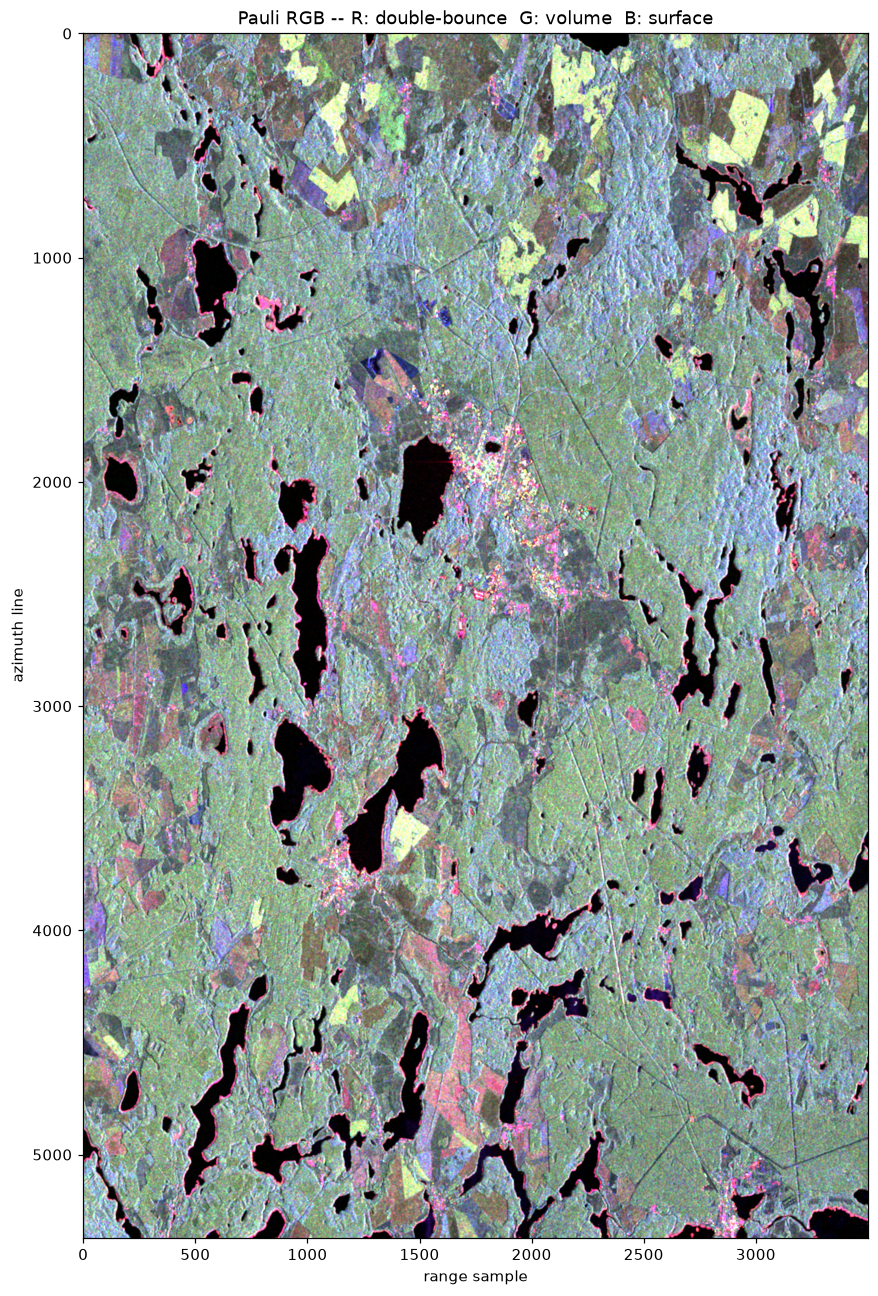

In [3]:
# Build the Pauli coherency matrix T3 and render it as a Pauli RGB false-colour composite.

# 1. coherency_t3 forms the Pauli scattering vector k = (S_HH+S_VV, S_HH-S_VV, sqrt(2)*S_HV)/sqrt(2)
#    per pixel, then box-averages its outer product k*k^H over a SIZE x SIZE window into the
#    3x3 coherency matrix T3 (returned as a dict of its named entries, e.g. t11/t22/t33 for the
#    diagonal, which is the classic Pauli decomposition's three mechanism powers).
t3 = polsar.coherency_t3(hh, hv, vh, vv, size=SIZE)

# 2. Total scattered power (span) is the trace of T3 -- the sum of the three Pauli mechanism
#    powers. Report it in dB to sanity-check the data (uncalibrated, so these are relative
#    numbers, not physical sigma0).
span = t3["t11"] + t3["t22"] + t3["t33"]
print(f"span (uncalibrated power) dB percentiles (1/50/99th): "  # span percentiles
      f"{10 * np.log10(np.nanpercentile(span, [1, 50, 99])).round(1)}")


# 3. Percentile-stretch a single band to [0, 1] for display, clipping outliers beyond the
#    lo/hi percentiles and replacing any remaining NaN with 0.
def stretch(x, lo=2, hi=98):
    a, b = np.nanpercentile(x, [lo, hi])  # 2nd and 98th percentile
    return np.nan_to_num(np.clip((x - a) / (b - a), 0, 1))  # stretch to [0, 1], NaN -> 0


# 4. Classic Pauli RGB convention: red = t22 (double-bounce / even-bounce, |S_HH-S_VV|^2),
#    green = t33 (volume / depolarising, 2*|S_HV|^2), blue = t11 (surface / odd-bounce,
#    |S_HH+S_VV|^2). Take the square root first since these are powers but amplitude is what
#    should be stretched for a natural-looking composite.
pauli_rgb = np.dstack([stretch(np.sqrt(t3["t22"])), stretch(np.sqrt(t3["t33"])), stretch(np.sqrt(t3["t11"]))])

# 5. Display the composite.
plt.figure(figsize=(8, 12))
plt.imshow(pauli_rgb)  # the Pauli RGB composite
plt.title("Pauli RGB -- R: double-bounce  G: volume  B: surface")  # title
plt.xlabel("range sample"); plt.ylabel("azimuth line")  # axis labels
plt.tight_layout()  # arrange

The scene is immediately legible without any land-cover labels: the many dark, irregularly
shaped patches are lakes (this is lake-district terrain), green dominates where forest covers
the moraine hills, pale yellow-green patches are agricultural fields, and one unmistakable
bright pink/white cluster (around the image centre) is a village -- real double-bounce
scattering from buildings, the same signature `07_03_01_07_DualPol.ipynb` picked out near Cox's
Bazar airport with only two channels; here it is sharper, because HH and VV are both available
to form the double-bounce Pauli term directly rather than inferring it from the dual-pol m-chi
decomposition's phase.

### Quad-pol H/alpha/anisotropy

`h_alpha_quad` solves the per-pixel 3x3 eigenproblem (vectorised: every pixel's coherency
matrix at once) for entropy (mechanism randomness, log base 3 so it still runs 0-1 for three
mechanisms), the mean alpha angle (0 degrees surface, 90 degrees double-bounce or depolarised
cross-pol -- the same convention as the dual-pol case, just with a cleaner physical basis to
work from) and anisotropy (contrast between the two weaker mechanisms).


entropy     5th/50th/95th percentile: 0.69 / 0.85 / 0.94


alpha       5th/50th/95th percentile: 31.27 / 43.11 / 52.27


anisotropy  5th/50th/95th percentile: 0.10 / 0.26 / 0.53


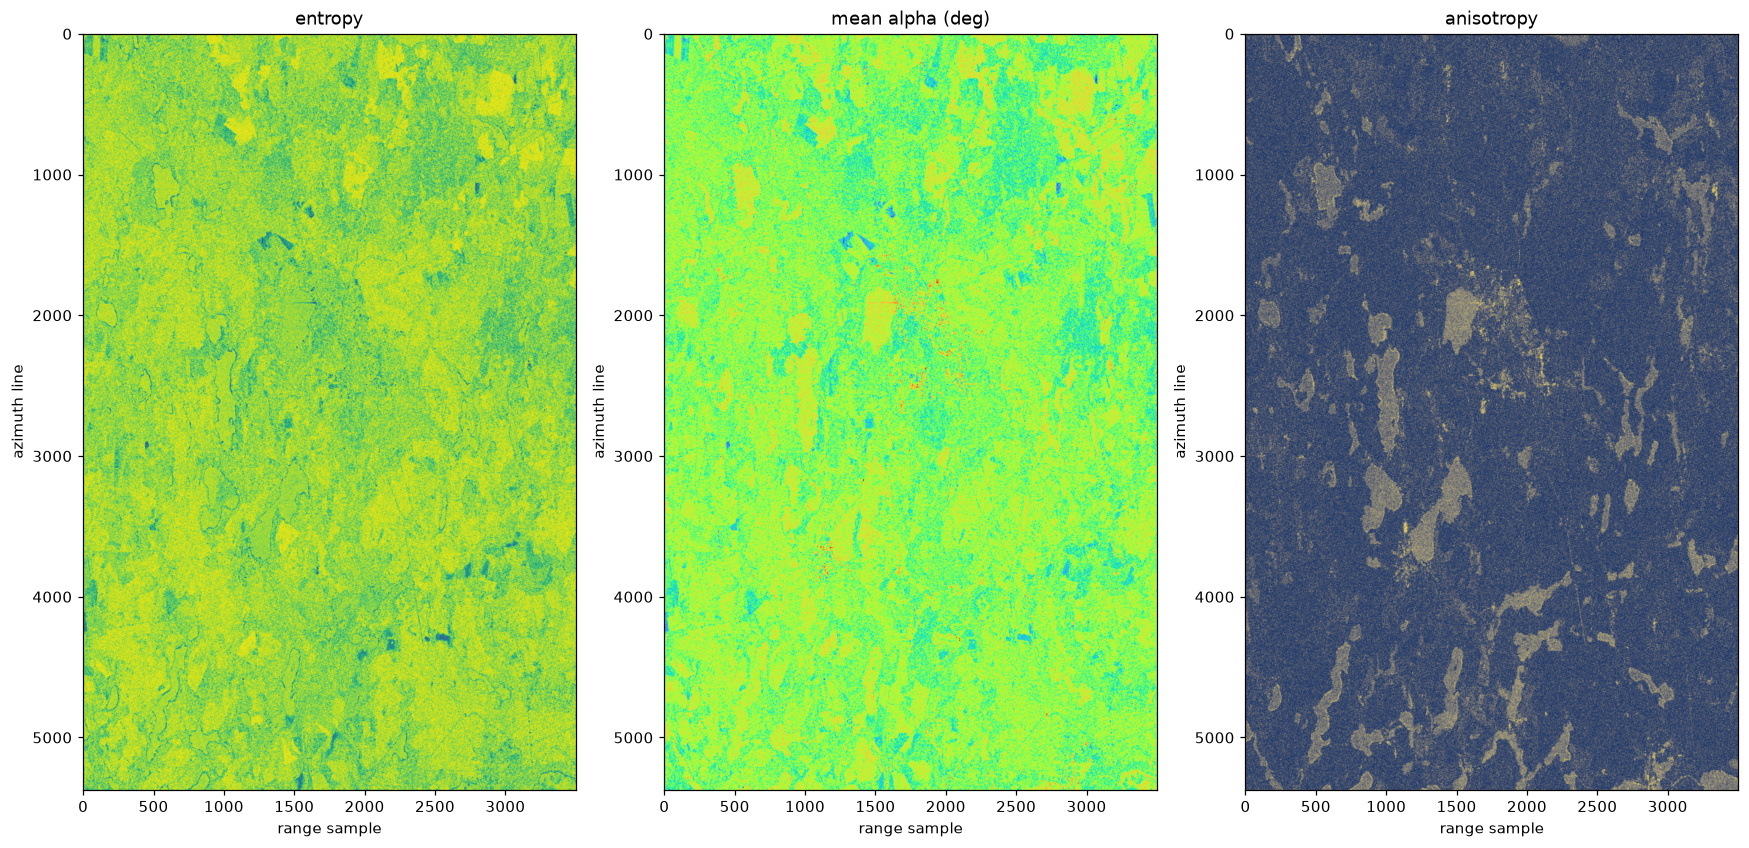

In [4]:
# Decompose T3 into entropy, mean alpha angle and anisotropy (Cloude-Pottier H/alpha/A), then
# map all three across the scene.

# 1. h_alpha_quad performs the per-pixel 3x3 eigendecomposition of T3 (vectorised over every
#    pixel at once) and returns entropy H (mechanism randomness, log base 3 so it ranges 0-1
#    for three eigenvalues), mean alpha (0 deg = surface/odd-bounce, 90 deg = double-bounce or
#    depolarised cross-pol scattering) and anisotropy (contrast between the two weaker,
#    non-dominant eigenvalues/mechanisms).
ha = polsar.h_alpha_quad(**t3)

# 2. Print the 5th/50th/95th percentile of each parameter as a quick numeric summary before
#    plotting.
for k in ("entropy", "alpha", "anisotropy"):
    lo, mid, hi = np.nanpercentile(ha[k], [5, 50, 95])  # percentiles of the layer
    print(f"{k:11s} 5th/50th/95th percentile: {lo:.2f} / {mid:.2f} / {hi:.2f}")  # print them

# 3. Show entropy, mean alpha and anisotropy side by side as three separate maps, each with a
#    colormap and value range suited to its physical meaning (entropy and anisotropy are
#    bounded 0-1, alpha runs 0-90 degrees).
fig, axes = plt.subplots(1, 3, figsize=(16, 9))
axes[0].imshow(ha["entropy"], cmap="viridis", vmin=0, vmax=1)  # entropy
axes[0].set_title("entropy")  # title
axes[1].imshow(ha["alpha"], cmap="turbo", vmin=0, vmax=90)  # mean alpha
axes[1].set_title("mean alpha (deg)")  # title
axes[2].imshow(ha["anisotropy"], cmap="cividis", vmin=0, vmax=1)  # anisotropy
axes[2].set_title("anisotropy")  # title
for ax in axes:  # for every panel
    ax.set_xlabel("range sample"); ax.set_ylabel("azimuth line")  # axis labels
plt.tight_layout()  # arrange

### The H-alpha plane and Cloude-Pottier zones

`h_alpha_classify` is the same function `07_03_01_07_DualPol.ipynb` used for Sentinel-1's
dual-pol H-alpha plane -- the zone boundaries and the eigenvalue-ratio math underneath are
identical regardless of whether entropy and alpha came from a 2x2 or 3x3 eigendecomposition, so
it applies to quad-pol output completely unchanged.


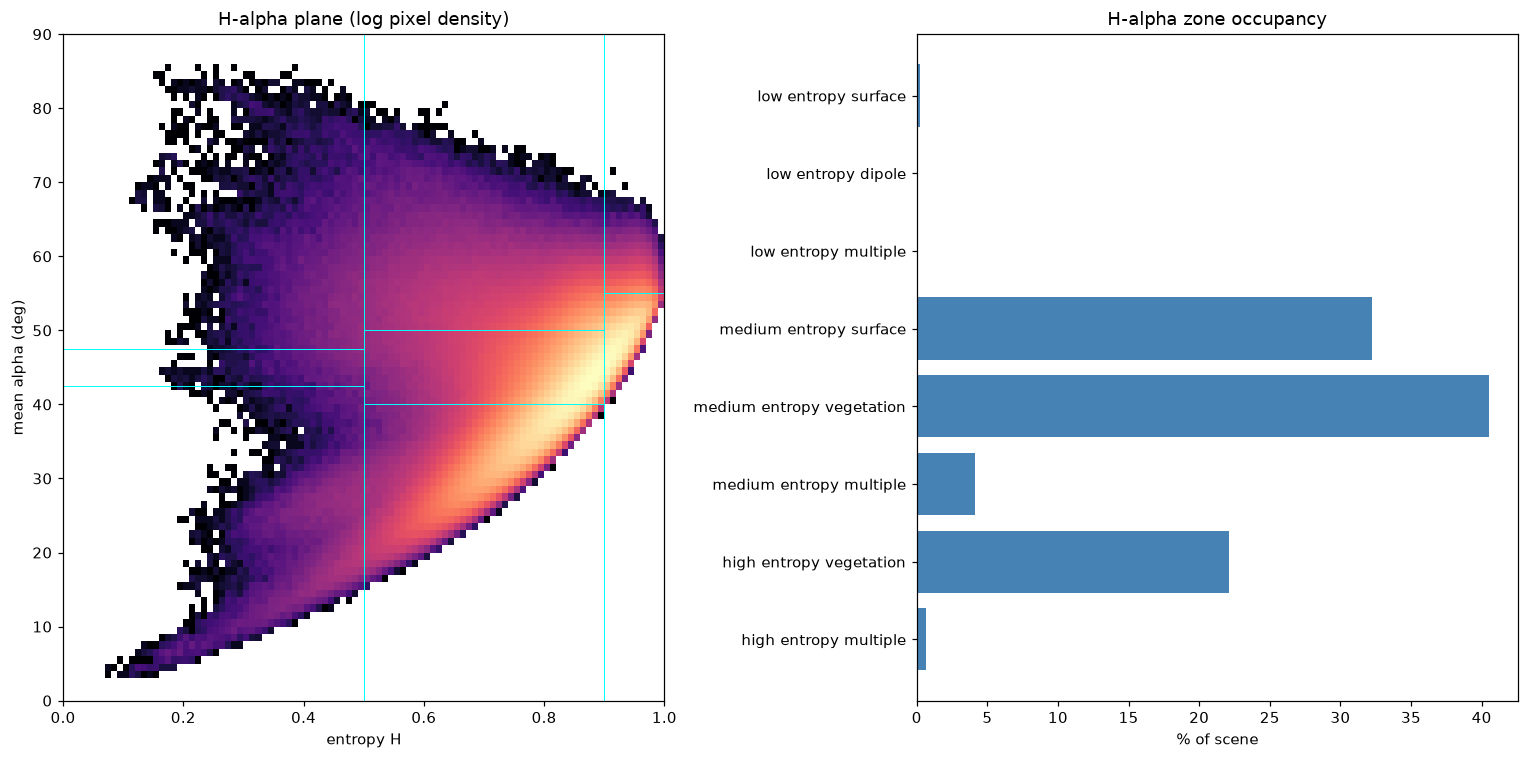

In [5]:
# Plot the H-alpha plane (pixel density with Cloude-Pottier zone boundaries overlaid) and the
# scene's occupancy of each zone.

import pandas as pd
import xarray as xr  # labelled arrays

fig, axes = plt.subplots(1, 2, figsize=(14, 7))  # two panels

# 1. Flatten entropy and alpha to 1D and keep only finite pixels (edges/invalid pixels produce
#    NaN) for the scatter/density plot below.
h, a = np.ravel(ha["entropy"]), np.ravel(ha["alpha"])
ok = np.isfinite(h) & np.isfinite(a)  # pixels with valid entropy and alpha

# 2. 2D histogram (log-scaled pixel density) of every valid pixel's (entropy, alpha) pair --
#    this is the classic H-alpha plane used to visualise scattering-mechanism diversity across
#    a whole scene at once.
axes[0].hist2d(h[ok], a[ok], bins=(100, 90), range=[[0, 1], [0, 90]], cmap="magma",
              norm=plt.matplotlib.colors.LogNorm())

# 3. Overlay the Cloude-Pottier zone boundaries (the same fixed rectangles h_alpha_classify
#    uses to label pixels below) as reference rectangles on top of the density plot.
for (h0, h1), (a0, a1) in polsar.H_ALPHA_ZONES.values():
    # outline of each H-alpha zone
    axes[0].plot([h0, h1, h1, h0, h0], [a0, a0, a1, a1, a0], color="cyan", lw=0.6)
# labels and title
axes[0].set(xlabel="entropy H", ylabel="mean alpha (deg)", title="H-alpha plane (log pixel density)")

# 4. Classify every pixel into its Cloude-Pottier zone number using the same function the
#    dual-pol tutorial used -- the zone geometry is identical regardless of whether H/alpha
#    came from a 2x2 or 3x3 eigendecomposition. Wrap the arrays in xr.DataArray since
#    h_alpha_classify expects labelled data.
zones = polsar.h_alpha_classify(xr.DataArray(ha["entropy"]), xr.DataArray(ha["alpha"])).values

# 5. Build a {zone number: zone name} lookup from H_ALPHA_ZONES's keys (formatted like
#    "Z5 <description>") for labelling the bar chart below.
zone_names = {int(k[1]): k.split(" ", 1)[1] for k in polsar.H_ALPHA_ZONES}

# 6. Compute what fraction of valid (finite-entropy) pixels fall in each zone, dropping zone 0
#    (invalid/unclassified) and expressing the rest as percentages.
pix = zones[np.isfinite(ha["entropy"])]
counts = pd.Series(pix).value_counts(normalize=True).sort_index() * 100  # share of pixels in each zone (%)
counts = counts[counts.index > 0]  # drop code 0 (no zone)

# 7. Horizontal bar chart of zone occupancy, so the reader can see at a glance which
#    scattering-mechanism/randomness regimes dominate the scene.
axes[1].barh([zone_names.get(i, str(i)) for i in counts.index], counts.values, color="steelblue")
axes[1].set(xlabel="% of scene", title="H-alpha zone occupancy")  # labels and title
plt.tight_layout()  # arrange

Real quad-pol data spreads across the *whole* H-alpha plane -- medium- and high-entropy
vegetation zones (Z5, Z2) are well populated, not just the low-alpha "surface" column the
dual-pol tutorial's own H-alpha plane was confined to.

## Quad-pol versus dual-pol, on the same real pixels

`07_03_01_07_DualPol.ipynb` noted that dual-pol alpha stays compressed into a narrow low range
because only two channels are available. That claim can now be checked directly: build a
dual-pol C2 from just two of this *same* scene's four real channels (HH, HV -- the pair an
HH-transmitting dual-pol sensor would actually deliver) with `covariance_c2`/`h_alpha_dual`,
and compare its alpha distribution against the quad-pol one above, pixel-for-pixel on the same
ground.


quad-pol alpha: 5/50/95th pct = [31.3 43.1 52.3]


dual-pol alpha: 5/50/95th pct = [11.6 20.4 30.5]


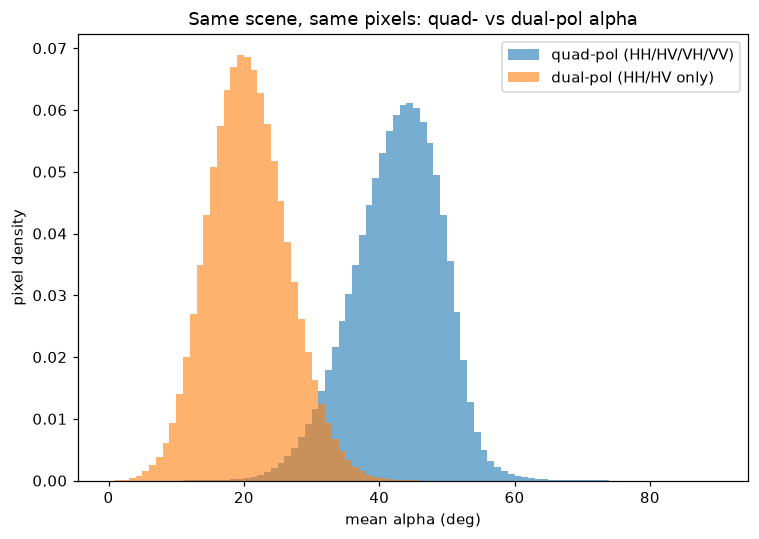

In [6]:
# Build a dual-pol C2 covariance matrix from just HH and HV (the same real scene), and compare
# its H/alpha output directly against the quad-pol result above, pixel-for-pixel.

# 1. covariance_c2 box-averages the 2x2 dual-pol covariance matrix from HH and HV only --
#    simulating what an HH-transmitting dual-pol sensor would actually deliver, using the same
#    SIZE x SIZE multilook window as everywhere else in this notebook for a fair comparison.
c2 = polsar.covariance_c2(hh, hv, size=SIZE)

# 2. h_alpha_dual performs the analogous 2x2 eigendecomposition for the dual-pol case (same
#    physical quantities, entropy/alpha, just derived from less information than the quad-pol
#    3x3 version above).
ha_dual = polsar.h_alpha_dual(**c2)

# 3. Overlay normalised (density) histograms of quad-pol alpha and dual-pol alpha over the same
#    pixels, so any difference in spread/location reflects the information lost by having only
#    two channels rather than a difference in scene content.
fig, ax = plt.subplots(figsize=(7, 5))
bins = np.linspace(0, 90, 91)  # alpha bins of 1 degree
# alpha from the quad-pol decomposition
ax.hist(np.ravel(ha["alpha"])[ok], bins=bins, density=True, alpha=0.6, label="quad-pol (HH/HV/VH/VV)")
# alpha from the dual-pol (HH, HV) subset
ax.hist(np.ravel(ha_dual["alpha"])[np.isfinite(np.ravel(ha_dual["alpha"]))], bins=bins, density=True,
       alpha=0.6, label="dual-pol (HH/HV only)")
# labels and title
ax.set(xlabel="mean alpha (deg)", ylabel="pixel density", title="Same scene, same pixels: quad- vs dual-pol alpha")
ax.legend()  # legend
plt.tight_layout()  # arrange

# 4. Print percentile summaries for both so the visual spread difference is backed by numbers:
#    dual-pol alpha should be narrower and shifted lower, since HH/HV alone cannot form the
#    S_HH - S_VV double-bounce term that drives alpha toward 90 degrees.
print(f"quad-pol alpha: 5/50/95th pct = {np.nanpercentile(ha['alpha'], [5, 50, 95]).round(1)}")
# dual-pol alpha percentiles
print(f"dual-pol alpha: 5/50/95th pct = {np.nanpercentile(ha_dual['alpha'], [5, 50, 95]).round(1)}")

The dual-pol histogram is visibly narrower and shifted lower -- real confirmation, not just a
simulated illustration, of why dual-pol H/alpha is a weaker discriminator than quad-pol: with
only HH and HV, there is no way to form the $S_{HH}-S_{VV}$ double-bounce term at all, so
alpha can never climb as high as it legitimately does here (the village cluster, for instance)
once HH, VV and their phase difference are all available.

## Takeaways and limitations

- `geolattice.rsense.sar.polsar.coherency_t3` and `h_alpha_quad` are new, genuinely sensor-agnostic
  additions (any quad-pol product -- RADARSAT-2, ALOS-2, NISAR -- feeds them the same way);
  `h_alpha_classify` needed no change at all to work on their output.
- **Freeman-Durden and other model-based quad-pol decompositions (surface/double-bounce/volume
  power split from C3/T3) are not implemented.** Several published versions differ in their
  exact volume-scattering branch and normalisation constants, and getting that wrong is a worse
  outcome than not having it -- a real gap, left as one rather than risking a subtly incorrect
  formula.
- No radiometric calibration was applied (this product's `lutSigma`/`lutBeta`/`lutGamma`
  structure is the same family `07_03_02_01_RADARSAT_GRD.ipynb` already reads for RCM, so wiring
  it up for RS2 is mechanical, not a research question) -- harmless here since entropy, alpha
  and anisotropy are scale-invariant ratios, but the `span`/Pauli-power values printed above are
  relative, uncalibrated numbers, not physical sigma0.
- No terrain correction or geocoding -- results are shown in the SLC's own radar geometry, as
  for every other raw (non-ARD) RADARSAT product in this series.

### Compact-pol and L-band, briefly

- **Compact-pol** (circular transmit, H+V receive; RCM, NISAR option) approximates much of this
  with a wider swath and half the data rate -- `07_03_02_00_RADARSAT_intro.ipynb` and
  `geolattice.rsense.sar.radarsat`'s `compact_pol_mchi` cover RCM's version.
- **L-band** (23-24 cm, NISAR, ALOS-2) penetrates forest canopy far better than C-band and is
  much more sensitive to biomass -- the same H/alpha/Pauli tools used here apply unchanged to
  L-band quad-pol data.

#### References

- Cloude, S. R., & Pottier, E. (1997). *An entropy based classification scheme for land
  applications of polarimetric SAR.* IEEE TGRS, 35(1), 68-78.
- Lee, J. S., & Pottier, E. (2009). *Polarimetric Radar Imaging: From Basics to Applications.*
  CRC Press.
- Freeman, A., & Durden, S. L. (1998). *A three-component scattering model for polarimetric SAR
  data.* IEEE TGRS, 36(3), 963-973. (the decomposition deliberately not implemented here)
